# Import Libraries

In [1]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests

# Download Financial Data

Download 5 years of USD Index. Columns Volume, Dividends and Stock Splits are not required, since they are constant and equal to 0.0

In [2]:
ticker_symbol = 'DX-Y.NYB'

ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='5y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df

/Users/sakis/projects/msc_dws/101-MachineLearning/02-KNN-TimeseriesForecasting/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/sakis/projects/msc_dws/101-MachineLearning/02-KNN-TimeseriesForecasting/.venv/lib/python3.14/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Users/sakis/projects/msc_dws/101-MachineLearning/02-KNN-TimeseriesForecasting/.venv/lib/python3.14/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future vers

,Date,Open,High,Low,Close
0,2021-10-28 00:00:00-04:00,93.879997,93.970001,93.279999,93.349998
1,2021-10-29 00:00:00-04:00,93.360001,94.300003,93.320000,94.120003
2,2021-11-01 00:00:00-04:00,94.129997,94.309998,93.860001,93.879997
3,2021-11-02 00:00:00-04:00,93.930000,94.129997,93.820000,94.089996
4,2021-11-03 00:00:00-04:00,94.120003,94.209999,93.820000,93.860001
...,...,...,...,...,...
1252,2026-10-22 00:00:00-04:00,101.709999,101.879997,101.449997,101.610001
1253,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998
1254,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999
1255,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000


# Construct Line Plot of HLC Data

In [3]:
df.describe()

,Open,High,Low,Close
count,1257.000000,1257.000000,1257.000000,1257.000000
mean,102.254445,102.587455,101.932184,102.267045
std,3.812000,3.864845,3.746385,3.808903
min,93.360001,93.970001,93.279999,93.349998
25%,99.120003,99.400002,98.860001,99.160004
50%,102.300003,102.629997,101.989998,102.300003
75%,104.620003,105.010002,104.260002,104.669998
max,114.190002,114.779999,113.330002,114.110001


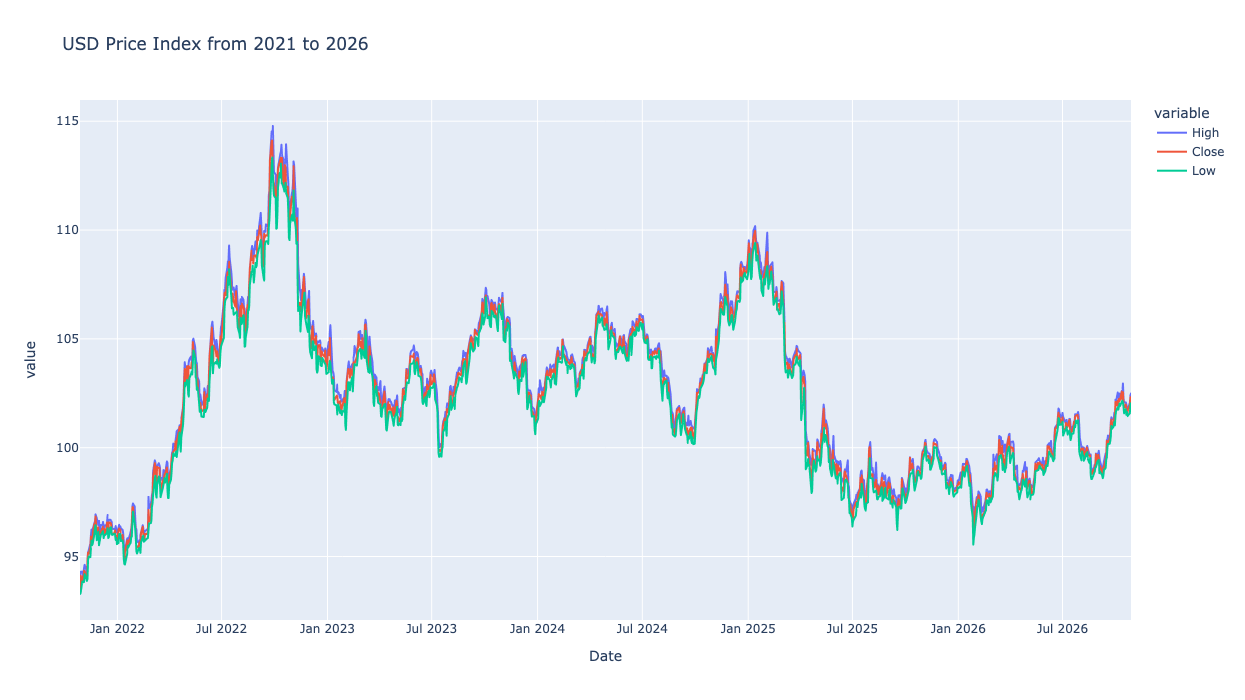

In [4]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index from 2021 to 2026')
fig.update_layout(width=1200, height=700)
fig.show()

In [5]:
# Οπτικά και μόνο, φαίνεται ότι μπορούν οι συγκεκριμένες χρονοσειρές να είναι στάσιμες, καθώς μπορεί να πει κανείς πως παρά
# τις μεγάλες διακυμάνσεις υπάρχει μια μέση τιμή κοντά γύρω στο 102-103 η οποία διατηρείται στο διάστημα που παρατηρούμε

In [6]:
from statsmodels.tsa.stattools import adfuller, kpss

results = {}
for ts in ["High", "Low", "Close"]:
    for i, f in enumerate([adfuller, kpss]):
        res = f(df[ts].dropna(), result_object=True)
        if ts not in results:
            results[ts] = {}
        results[ts][f.__name__] = res

limit = 0.05
for k, v in results.items():
    if any([
        v["adfuller"].pvalue >= limit,
        v["kpss"].pvalue < limit,
    ]):
        print(f"{k} is not stationary")

SyntaxError: unterminated f-string literal (detected at line 17) (28501562.py, line 17)

# Train-Test Split

Test set should start 1 time step after the end of train set.

In [ ]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

# Construct Timeframes

*   x = <x[0], x[1], x[2], ... x[H-1]>
*   y = x[H]

where x is (Open(t), High(t), Low(t), Close(t))

**Important: Past target must be included in x to achieve good accuracy**

In [ ]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

# Verify Timeframes

In [ ]:
train_df.head(5)

In [ ]:
x_train, y_train = construct_timeframes(train_df, H=4)
print('x:', x_train[0],'\ny:', y_train[0])

# Fit Linear Regression Model

Setting H = 30

In [ ]:
x_train, y_train = construct_timeframes(train_df, history_size)
x_test, y_test = construct_timeframes(test_df, history_size)

x_train.shape, y_train.shape, x_test.shape, y_test.shape

In [ ]:
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_train)
train_mae = mean_absolute_error(y_true=y_train, y_pred=y_pred)
y_pred = model.predict(x_test)
test_mae = mean_absolute_error(y_true=y_test, y_pred=y_pred)

metrics_df = pd.DataFrame({'Dataset': ['Train', 'Test'], 'MAE': [train_mae, test_mae]})
ax = sns.barplot(metrics_df, x='Dataset', y='MAE', edgecolor='black')
ax.set_title('Train-Test MAE of Linear Regression with H=30')
ax

# Visualize Predictions

In [ ]:
train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

# Create figure
fig = go.Figure()

# Training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train',
    line=dict(color='royalblue', width=2)
))

# Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

# Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_pred),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='USD Price Index — Close Price Prediction',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)

fig.show()

# Apply Log Returns Transformation

In [ ]:
vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars] = np.log(df_logr[vars]/df_logr[vars].shift(1))
df_logr

# Convert Log Returns to Absolute Price

$lr_{t+1} = \ln(\frac{y_{t+1}}{y_{t}})$

$y_{t+1} = y_t * e^{lr_{t+1}}$

Inevitably, the first sample will be lost, as its log-return transformation cannot be defined (x[-1] does not exist).

In [ ]:
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

In [ ]:
valid_df = pd.DataFrame({
    'Date': df['Date'].iloc[: 6],
    'Close': df['Close'].iloc[: 6],
    'CLose-Log-Returns': df_logr['Close'].iloc[: 6]
})
valid_df

In [ ]:
log_returns_to_absolute_prices(
    prices=valid_df['Close'].iloc[: -1].to_numpy(),
    log_returns=valid_df['CLose-Log-Returns'].iloc[1:].to_numpy()
)

# Check Whether High can Predict Close

Variables that can estimate the target variable are considered beneficial.

In [ ]:
data = train_df[['Close', 'Open']]

# Computing log-returns (converting to stationary series).
data = np.log(data/data.shift(1)).dropna()

# Test up to history_size lags
results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)

# Extract p-values
p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
results_df = pd.DataFrame({'Lag (H)': list(p_values.keys()), 'P-value': list(p_values.values())})
results_df['Significant'] = results_df['P-value'] < 0.05
results_df

# Extracting Temporal Features

In [ ]:
# Calendar features
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

# US & NYSE holidays
us_holidays = holidays.country_holidays('US')
nyse_holidays = holidays.financial_holidays('NYSE')

# Global events
global_events = {
    'NewYearsDay': (1, 1),
    'ValentinesDay': (2, 14),
    'WomensDay': (3, 8),
    'AprilFools': (4, 1),
    'EarthDay': (4, 22),
    'LabourDay': (5, 1),
    'EnvironmentDay': (6, 5),
    'Halloween': (10, 31),
    'ChristmasEve': (12, 24),
    'ChristmasDay': (12, 25),
    'BoxingDay': (12, 26),
    'NewYearsEve': (12, 31),
}

event_dates = set(global_events.values())

# Combine US holidays, NYSE holidays, and global events
df['IsHoliday'] = df['Date'].dt.date.map(
    lambda d: int(
        d in us_holidays
        or d in nyse_holidays
        or (d.month, d.day) in event_dates
    )
)

df

In [ ]:
df['IsHoliday'].value_counts()